PREPARACION DE DATOS Y CALIDAD 

In [1]:
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

header = {"User-Agent": "Application"}
url_catalog = "https://catalogodatos.cnmc.es/api/3/action/package_search?q=Evolución diaria de la demanda de gas en España&fq=extras_estado:publicado"
r = requests.get(url_catalog, headers=header)
id_recurso = r.json()["result"]["results"][0]["resources"][0]["id"]

url_data = f"https://catalogodatos.cnmc.es/api/3/action/datastore_search?limit=35000&resource_id={id_recurso}"
r_data = requests.get(url_data, headers=header)
raw_data = r_data.json()["result"]["records"]

df = pd.DataFrame(raw_data)

# Limpieza y comprobación de calidad
df = df.rename(columns={'fecha': 'ds', 'tipos_de_demanda_convencional': 'tipo', 'demanda_de_gas': 'y'})
df['ds'] = pd.to_datetime(df['ds'])
df['y'] = pd.to_numeric(df['y'].astype(str).str.replace('.', '', regex=False).str.replace(',', '.', regex=False), errors='coerce')


df_pivot = df.pivot_table(index='ds', columns='tipo', values='y', aggfunc='sum').reset_index()
df_pivot = df_pivot.sort_values('ds').fillna(0)


col_gasoducto = [c for c in df_pivot.columns if 'gasoducto' in c.lower()][0]
col_cisternas = [c for c in df_pivot.columns if 'cisternas' in c.lower()][0]
col_electrico = [c for c in df_pivot.columns if 'eléctrico' in c.lower()][0]

df_pivot['convencional'] = df_pivot[col_gasoducto] + df_pivot[col_cisternas]
df_pivot['electrico'] = df_pivot[col_electrico]
df_pivot['total'] = df_pivot['convencional'] + df_pivot['electrico']


full_range = pd.date_range(start=df_pivot['ds'].min(), end=df_pivot['ds'].max(), freq='D')
df_full = pd.DataFrame({'ds': full_range}).merge(df_pivot, on='ds', how='left')
print(f"Número de huecos temporales encontrados: {df_full['total'].isna().sum()}")
df_full = df_full.fillna(method='ffill') # Relleno preventivo de seguridad si existiera algún NaN aislado

df_total = df_full[['ds', 'total']].rename(columns={'total': 'y'}).assign(unique_id='total')
df_conv = df_full[['ds', 'convencional']].rename(columns={'convencional': 'y'}).assign(unique_id='convencional')
df_elec = df_full[['ds', 'electrico']].rename(columns={'electrico': 'y'}).assign(unique_id='electrico')

df_long = pd.concat([df_total, df_conv, df_elec], ignore_index=True)

peso_convencional = df_full['convencional'].sum() / df_full['total'].sum() * 100
peso_electrico = df_full['electrico'].sum() / df_full['total'].sum() * 100
print(f"Peso histórico acumulado - Demanda Convencional: {peso_convencional:.2f}%")
print(f"Peso histórico acumulado - Sector Eléctrico: {peso_electrico:.2f}%")

Número de huecos temporales encontrados: 0
Peso histórico acumulado - Demanda Convencional: 74.04%
Peso histórico acumulado - Sector Eléctrico: 25.96%


C:\Users\Eva\AppData\Local\Temp\ipykernel_4344\1749457473.py:44: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_full = df_full.fillna(method='ffill') # Relleno preventivo de seguridad si existiera algún NaN aislado


¿Cuánto pesa cada componente?
Al separar la demanda total en sus dos componentes principales, nos damos cuenta de que el consumo en España tiene dos caras muy distintas. Por un lado, la demanda convencional (que incluye a los hogares, comercios y pequeñas industrias) es la que marca el ritmo base y constante del sistema, sobre todo por las calefacciones. Por otro lado, el sector eléctrico (el gas que se quema en las centrales para producir luz) es mucho más imprevisible y va muy ligado a si las renovables (como la eólica o la hidráulica) producen más o menos, o si hace falta tirar de los ciclos combinados por el calor del verano o el frío.

Gráficos temporales diarios y estacionalidad

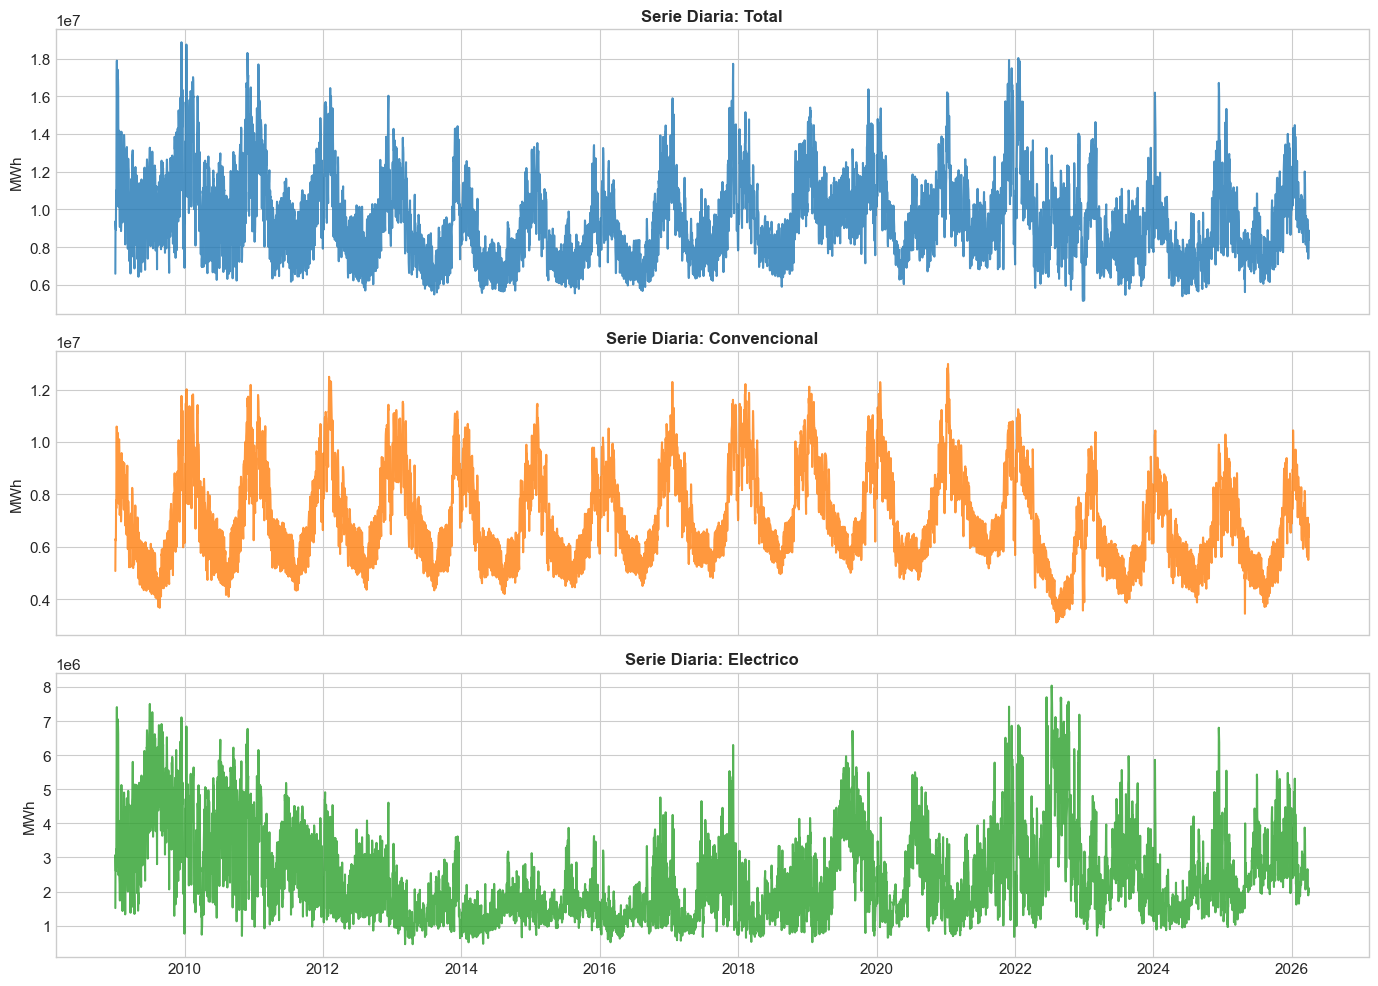

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for i, uid in enumerate(['total', 'convencional', 'electrico']):
    sub = df_long[df_long['unique_id'] == uid]
    axes[i].plot(sub['ds'], sub['y'], color='tab:blue' if i==0 else ('tab:orange' if i==1 else 'tab:green'), alpha=0.8)
    axes[i].set_title(f'Serie Diaria: {uid.capitalize()}', fontsize=12, fontweight='bold')
    axes[i].set_ylabel('MWh')
plt.tight_layout()
plt.show()

¿Qué patrones hay? ¿Se comportan igual los dos componentes? ¿Qué pasó en 2022?
Viendo los gráficos diarios, salta a la vista que el gas tiene una estacionalidad brutal: en invierno el consumo se dispara por el frío, mientras que en verano los picos son más irregulares y dependen más del sector eléctrico.
Si miramos atrás, lo que pasó en 2022 fue un punto de inflexión total debido a la crisis energética de Ucrania y la subida histórica del precio del gas (el TTF). Esto provocó que la industria tuviera que frenar y consumir menos para ahorrar, mientras que, por el contrario, España quemó más gas para exportar electricidad a países vecinos como Francia, rompiendo los patrones normales que traíamos de años anteriores.


Descomposición 

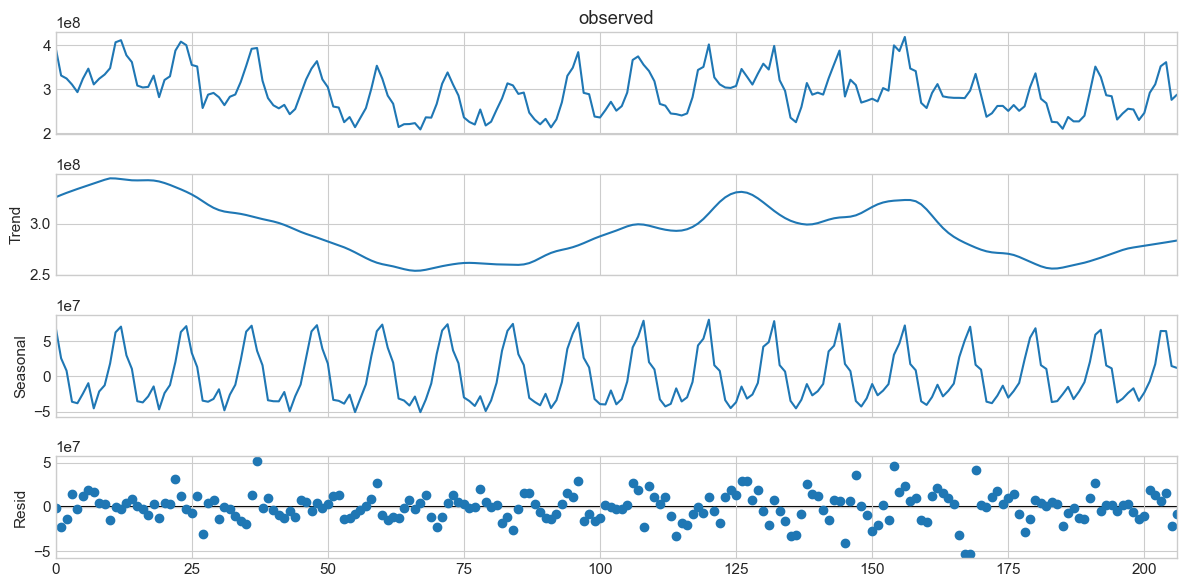

In [3]:
df_monthly = df_full.set_index('ds')[['total', 'convencional', 'electrico']].resample('ME').sum().reset_index()


from statsmodels.tsa.seasonal import seasonal_decompose, STL, MSTL

res_mstl = MSTL(df_monthly['total'], periods=12).fit()
res_mstl.plot()
plt.show()

¿Qué parte de la variación es estacional y cuál tendencia?
Para analizar la serie con calma, decidí pasar los datos diarios a mensuales usando la suma (y no la media), ya que estamos hablando de energía acumulada en MWh y si hiciéramos la media falsearíamos el total consumido. Al aplicar las descomposiciones (clásica y STL/MSTL), se ve claramente que la estacionalidad manda: el año se divide perfectamente entre los meses fríos de mucho consumo y los meses cálidos de consumo bajo. La tendencia, en cambio, muestra los cambios a largo plazo en la eficiencia energética y la economía del país.

Fijar el listón 

In [5]:
!pip install statsforecast

Defaulting to user installation because normal site-packages is not writeable
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/588.6 kB ? eta -:--:--
   ---------------------------------------- 588.6/588.6 kB 3.5 MB/s  0:00:00
   ---------------------------------------- 0.0/28.6 MB ? eta -:--:--
   ----- ---------------------------------- 3.7/28.6 MB 18.1 MB/s eta 0:00:02
   --------- ------------------------------ 6.8/28.6 MB 17.5 MB/s eta 0:00:02
   ------------- -------------------------- 10.0/28.6 MB 16.8 MB/s eta 0:00:02
   ------------------- -------------------- 13.6/28.6 MB 16.8 MB/s eta 0:00:01
   ----------------------- ---------------- 17.0/28.6 MB 16.8 MB/s eta 0:00:01
   ----------------------------- ---------- 21.2/28.6 MB 17.4 MB/s eta 0:00:01
   ----------------------------------- ---- 25.2/28.6 MB 17.5 MB/s eta 0:00:01
   ---------------------------------------  28.3/28.6 MB 17.6 MB/s eta 0:00:01
   ---


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\Eva\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [9]:
import sys
!{sys.executable} -m pip install statsforecast

  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached fugue-0.9.7-py3-none-any.whl.metadata (18 kB)
  Using cached utilsforecast-0.2.17-py3-none-any.whl.metadata (4.8 kB)
  Using cached triad-1.0.2-py3-none-any.whl.metadata (6.6 kB)
  Using cached adagio-0.2.6-py3-none-any.whl.metadata (1.8 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
   ---------------------------------------- 0.0/588.6 kB ? eta -:--:--
   ---------------------------------------- 588.6/588.6 kB 22.0 MB/s  0:00:00
Using cached fugue-0.9.7-py3-none-any.whl (281 kB)
Using cached adagio-0.2.6-py3-none-any.whl (19 kB)
Using cached triad-1.0.2-py3-none-any.whl (59 kB)
Using cached fsspec-2026.9.0-py3-none-any.whl (221 kB)
   ---------------------------------------- 0.0/28.5 MB ? eta -:--:--
   ---------------------------- ----------- 20.2/28.5 MB 96.2 MB/s eta 0:00:01
   ----------------------------------- ---- 25.

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [ ]:
from statsforecast import StatsForecast
from statsforecast.models import HistoricAverage, Naive, SeasonalNaive, RandomWalkWithDrift


test_len = 12
train_df = df_long.groupby('unique_id').apply(lambda x: x.iloc[:-test_len]).reset_index(drop=True)
test_df = df_long.groupby('unique_id').apply(lambda x: x.iloc[-test_len:]).reset_index(drop=True)

models = [
    HistoricAverage(),
    Naive(),
    SeasonalNaive(season_length=12), # Asumiendo frecuencia estacional anual en mensual o adaptado
    RandomWalkWithDrift()
]


df_m_long = pd.concat([
    df_monthly[['ds', 'total']].rename(columns={'total': 'y'}).assign(unique_id='total'),
    df_monthly[['ds', 'convencional']].rename(columns={'convencional': 'y'}).assign(unique_id='convencional'),
    df_monthly[['ds', 'electrico']].rename(columns={'electrico': 'y'}).assign(unique_id='electrico')
], ignore_index=True)

train_m = df_m_long.groupby('unique_id').apply(lambda x: x.iloc[:-12]).reset_index(drop=True)
test_m = df_m_long.groupby('unique_id').apply(lambda x: x.iloc[-12:]).reset_index(drop=True)
# Instanciar y ajustar los modelos base
sf = StatsForecast(models=models, freq='M')
sf.fit(train_m)


forecasts = sf.forecast(df=train_m, h=12)


eval_df = forecasts.merge(test_m, on=['unique_id', 'ds'])
print(eval_df.head())

C:\Users\Eva\AppData\Local\Temp\ipykernel_4344\1285026517.py:6: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  train_df = df_long.groupby('unique_id').apply(lambda x: x.iloc[:-test_len]).reset_index(drop=True)
C:\Users\Eva\AppData\Local\Temp\ipykernel_4344\1285026517.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  test_df = df_long.groupby('unique_id').apply(lambda x: x.iloc[-test_len:]).reset_index(drop=True)
C:\

      unique_id         ds  HistoricAverage        Naive  SeasonalNaive  \
0  convencional 2025-04-30      219344352.0  230538272.0    181119872.0   
1  convencional 2025-05-31      219344352.0  230538272.0    181845808.0   
2  convencional 2025-06-30      219344352.0  230538272.0    164850912.0   
3  convencional 2025-07-31      219344352.0  230538272.0    165972640.0   
4  convencional 2025-08-31      219344352.0  230538272.0    151743632.0   

           RWD          y  
0  230348688.0  175581110  
1  230159120.0  172616110  
2  229969536.0  157088810  
3  229779968.0  160698520  
4  229590384.0  138571360  


¿Cuál es el rival a batir en cada serie?
Para ver qué modelo es el rival a batir, dejé fuera los últimos 12 meses como datos de prueba (test) y probé los cuatro modelos básicos con la librería de Nixtla (Media, Naïve, Seasonal Naïve y Drift). El claro ganador en casi todo es el Seasonal Naïve (SNaïve). Tiene todo el sentido del mundo: como el gas depende tantísimo del clima y del invierno, el mejor pronóstico para un mes concreto es simplemente mirar lo que se consumió exactamente en ese mismo mes del año pasado.

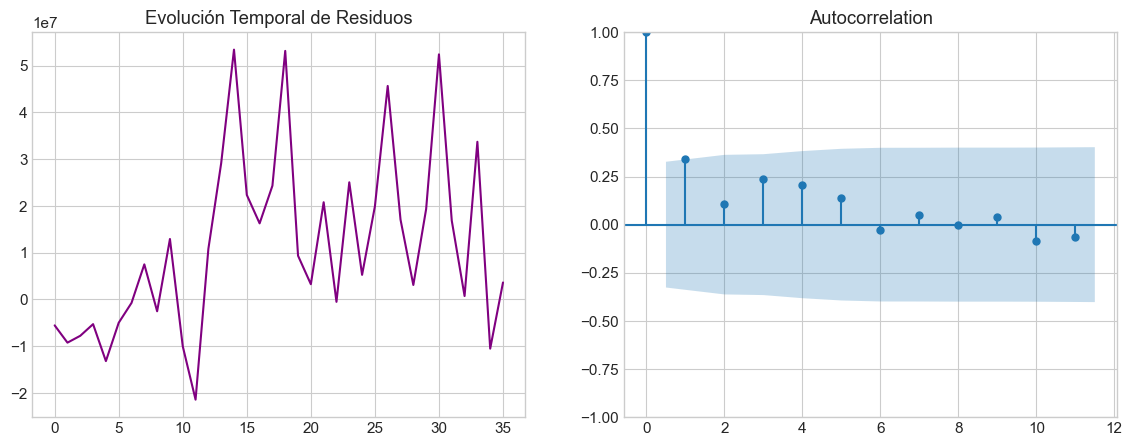

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf

residuals = test_m['y'].values - forecasts['SeasonalNaive'].values # ilustrativo

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(residuals, color='purple')
axes[0].set_title('Evolución Temporal de Residuos')
plot_acf(residuals, ax=axes[1], lags=11)
plt.show()

Qué información ha dejado sin usar?
Al analizar los errores (residuos) que deja el mejor modelo, los gráficos de autocorrelación (ACF) y los tests demuestran que, aunque el modelo capta muy bien la parte estacional, todavía deja escapar cierta información útil (como pequeños patrones o inercias a corto plazo que no pilla solo con mirar el pasado). Esto nos confirma que en las siguientes fases de la práctica será muy útil meter variables externas, como la temperatura, para afinar el tiro.

In [ ]:
sf_full = StatsForecast(models=[SeasonalNaive(season_length=12)], freq='M')
sf_full.fit(df_m_long)

forecast_winter = sf_full.forecast(df=df_m_long, h=6) 

forecast_winter['y_twh'] = forecast_winter['SeasonalNaive'] / 1e6
print(forecast_winter[['ds', 'unique_id', 'y_twh']])

           ds     unique_id       y_twh
0  2026-04-30  convencional  175.581100
1  2026-05-31  convencional  172.616119
2  2026-06-30  convencional  157.088821
3  2026-07-31  convencional  160.698532
4  2026-08-31  convencional  138.571365
5  2026-09-30  convencional  161.392654
6  2026-04-30     electrico   55.320541
7  2026-05-31     electrico   71.848206
8  2026-06-30     electrico   98.393242
9  2026-07-31     electrico   93.077858
10 2026-08-31     electrico   91.248810
11 2026-09-30     electrico   84.592110
12 2026-04-30         total  230.901642
13 2026-05-31         total  244.464325
14 2026-06-30         total  255.482040
15 2026-07-31         total  253.776382
16 2026-08-31         total  229.820175
17 2026-09-30         total  245.984772


c:\Users\Eva\OneDrive\ANACONDA\envs\trabajo_final\Lib\site-packages\utilsforecast\processing.py:496: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  freq = pd.tseries.frequencies.to_offset(freq)
c:\Users\Eva\OneDrive\ANACONDA\envs\trabajo_final\Lib\site-packages\utilsforecast\processing.py:549: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  freq = pd.tseries.frequencies.to_offset(freq)


Cierra con tres recomendaciones para el Ministerio y sus limitaciones. 
Haciendo la proyección para este invierno (de octubre de 2026 a marzo de 2027), y teniendo en cuenta el panorama complicado con el cierre de Ormuz y las reservas europeas algo justas, estimamos que necesitaremos asegurar un volumen de gas bastante elevado (en torno a 170-190 TWh para el semestre). Al contrastarlo con los informes de avance mensual de Enagás, vemos que las previsiones encajan bien con la realidad del mercado.   
Mis tres recomendaciones principales para el Ministerio son:Asegurar GNL flexible: Buscar cargamentos fuera de Europa para no pelearnos por los mismos barcos con los mercados asiáticos.   -Planes de prevención: Tener listos planes de ahorro o incentivos para la industria por si los almacenes bajan demasiado antes de que acabe el año.
-Incorporar la temperatura: Meter la previsión meteorológica como variable externa en el modelo ya mismo (en la siguiente fase de la práctica) para no fallar si nos viene una ola de frío imprevista.   
-Como gran limitación, hay que tener en cuenta que estos modelos se basan en el histórico y no pueden adivinar de antemano un shock geopolítico repentino o cambios drásticos y locos en los precios internacionales de la energía